# Módulo 4 — Criterios A, B y C

| | |
|---|---|
| **Código** | `criterios_abc.py` y `marcar_rojo.py` (en esta misma carpeta) |
| **Recibe** | la imagen mejorada (M1) y la máscara de la lesión (M3) |
| **Devuelve** | A (0-2), B (0-8), C (1-6), circularidad |

In [1]:
# Permite usar el código de las otras carpetas del repo
import sys
sys.path.insert(0, "../..")

# Recarga los cambios que hagas en los archivos .py sin reiniciar el cuaderno
%load_ext autoreload
%autoreload 2

import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch
from skimage import color

from modulos.m0_carga_de_datos import carga_de_datos
from modulos.m1_mejoramiento import mejoramiento
from modulos.m3_segmentacion import segmentacion
from modulos.m4_criterios_abc import criterios_abc, marcar_rojo
from modulos.m7_clasificacion_resultados.clasificacion_resultados import kappa_cohen
from modulos.herramientas import graficos
from modulos.herramientas.procesamiento_completo import procesar

graficos.aplicar_estilo()
COLORES = carga_de_datos.COLORES

## 1. Qué medimos y cómo

Este módulo recibe la imagen mejorada por M1 y la máscara de la lesión de M3, y calcula tres de los cuatro criterios de la regla ABCD (el D lo calcula M5), más la circularidad. Todo se mide sobre **nuestra** máscara y no sobre la de PH2, porque es la que el programa va a tener con una imagen nueva. La de PH2 la usamos sólo en la sección 8, para ver si un error viene de la segmentación o del criterio.

Los umbrales se eligen con las 140 imágenes de entrenamiento, probando una lista de valores y quedándonos con el mejor (igual que la grilla de M3), y al final se evalúa una sola vez en las 60 de prueba.

**A, asimetría.** Calculamos el centro de la lesión y sus dos ejes principales: el largo, por donde la lesión se estira más, y su perpendicular. Los ejes salen de los momentos de segundo orden, que dicen hacia dónde está más "estirada" la nube de píxeles de la máscara. Después reflejamos la máscara sobre cada eje, como si la dobláramos sobre el eje, y medimos qué fracción de la lesión queda afuera de su reflejo: 0 si es simétrica, y más cuanto más asimétrica. Un eje es asimétrico si esa fracción supera un umbral, y A es la cantidad de ejes asimétricos (0, 1 o 2).

**B, borde.** Dividimos el contorno en 8 sectores de 45°, contados desde el eje largo para que el resultado no dependa de cómo esté girada la foto. En cada sector medimos el gradiente del brillo (filtro de Sobel sobre V): cuanto más de golpe pasa la lesión a la piel, más alto es el gradiente. En cada punto del contorno tomamos el gradiente más alto a menos de 5 px, por si nuestro contorno quedó un poco corrido del borde real. Probamos dos versiones:
- cruda: el gradiente tal cual;
- normalizada: el gradiente dividido por el salto de brillo entre la piel y la lesión en ese sector. Así mide qué tan **rápido** cambia el brillo y no **cuánto**, y una lesión clara con el borde nítido no queda castigada por contrastar poco.

Los puntos del contorno pegados al marco de la foto o a la viñeta no cuentan, ya que ahí la lesión no termina sino que la cortó la foto. Un sector es abrupto si supera un umbral, y B es la cantidad de sectores abruptos (0 a 8).

**C, color.** Cada píxel de la lesión se asigna al más parecido de seis colores de referencia (blanco, rojo, marrón claro, marrón oscuro, azul grisáceo y negro), y un color está presente si ocupa más de un porcentaje mínimo de la lesión. C es la cantidad de colores presentes. Tres detalles:
- Comparamos en HSV, pero pasando cada color a un punto de un cono: el matiz es un ángulo (así 0 y 1 son el mismo rojo), el radio es S·V y la altura es V. En el cono, los colores muy oscuros o grises, donde el matiz no significa nada, quedan juntos cerca del eje.
- Antes de comparar dividimos cada canal por el color de la piel de la misma foto.
- También comparamos con la piel misma: un píxel que se parece más a la piel que a cualquiera de los seis colores no cuenta para ninguno.

**Circularidad.** $4\pi A / P^2$, con $A$ el área y $P$ el perímetro: vale 1 para un círculo y menos cuanto más irregular es el contorno. No tiene umbral.

**Cómo comparamos con el dermatólogo.** Para A y C usamos el κ de Cohen, que mide cuánto coinciden dos evaluadores descontando lo que coincidirían por azar. Por ejemplo, si el dermatólogo pone A = 0 en más de la mitad de las imágenes, alguien que ponga siempre A = 0 coincide muchas veces sin haber mirado nada, y su κ es 0. κ = 1 es acuerdo perfecto y entre 0,41 y 0,60 se considera un acuerdo moderado.

PH2 no anota B, así que para B (y para la circularidad) miramos qué tan bien separa los nevos comunes de las lesiones sospechosas (nevos atípicos y melanomas) con el AUC, la probabilidad de que una lesión sospechosa elegida al azar tenga un valor más alto que un nevo común elegido al azar. 0,5 es no separar nada, 1 es separar perfecto, y un AUC menor que 0,5 quiere decir que separa al revés.

In [2]:
def auc(puntaje, positivo):
    """Probabilidad de que una lesión sospechosa al azar tenga más puntaje que un nevo común al azar.

    Se comparan todos los pares (sospechosa, común); los empates cuentan medio.
    """
    puntaje, positivo = np.asarray(puntaje, float), np.asarray(positivo, bool)
    p, n = puntaje[positivo][:, None], puntaje[~positivo][None, :]
    return float(np.mean(p > n) + 0.5 * np.mean(p == n))


def dibujar_ejes(ax, fondo, mascara, titulo=""):
    """La lesión con sus dos ejes (el mayor continuo) y, punteado, su reflejo sobre el eje mayor."""
    f_mayor, f_menor, angulo = criterios_abc.fracciones_asimetria(mascara)
    filas, columnas = np.nonzero(mascara)
    cf, cc, largo = filas.mean(), columnas.mean(), max(np.ptp(filas), np.ptp(columnas)) / 2
    graficos.mostrar(ax, fondo, f"{titulo}\nsin superponer: {f_mayor:.2f} y {f_menor:.2f}")
    ax.title.set_fontsize(7)
    graficos.contorno(ax, mascara)
    ax.contour(criterios_abc.reflejo(mascara, "mayor").astype(float), levels=[0.5],
               colors="cyan", linewidths=1, linestyles=":")
    for grados, estilo in ((angulo, "-"), (angulo + 90, "--")):
        dc, df = largo * np.cos(np.radians(grados)), largo * np.sin(np.radians(grados))
        ax.plot([cc - dc, cc + dc], [cf - df, cf + df], estilo, color="cyan", lw=1)
    ax.set_xlim(0, mascara.shape[1] - 1)
    ax.set_ylim(mascara.shape[0] - 1, 0)

## 2. Los colores de referencia

Para saber a qué color se parece cada píxel necesitamos un "color modelo" de cada uno. Los sacamos de PH2: en 27 de las 200 imágenes los autores pintaron zonas de la lesión y anotaron de qué color son. Usamos sólo las que son de entrenamiento.

Antes de usarlas comprobamos que el número de "Label" del archivo es el código de color de PH2 (1 blanco, 2 rojo, 3 marrón claro, 4 marrón oscuro, 5 azul grisáceo, 6 negro): en 44 de las 48 zonas de color de toda la base, el color que dice el archivo figura entre los que el dermatólogo anotó para esa imagen. Las 4 restantes son inconsistencias de la propia base, y las dejamos.

**El rojo.** PH2 tiene imágenes con la etiquete que indica presencia de rojo, pero ninguna no tienen ninguna zona pintada de rojo, así que tomamos la decisión de marcarlas nosotros. En las 7 imágenes de entrenamiento en las que el dermatólogo anotó rojo, rodeamos a mano las zonas claramente rojas con `marcar_rojo.py`, que abre cada imagen, deja dibujar polígonos y guarda la máscara en `datos/anotaciones_rojo/`. Sólo en una (IMD035) vimos una zona claramente roja; en las otras 6 no, y quedaron sin marcar. Así que la referencia del rojo sale de una sola zona, y hay que tomarla con cuidado. A partir de ahí el rojo se trata igual que los otros colores. Las imágenes de prueba no se marcaron, para no usarlas en ningún ajuste.

In [3]:
rojas = marcar_rojo.imagenes_con_rojo()
marcadas = [n for n in rojas if marcar_rojo.ruta_de(n).exists()]
print(f"Imágenes de entrenamiento con rojo según el dermatólogo: {len(rojas)} ({', '.join(rojas)})")
print(f"Marcadas por nosotros: {len(marcadas)}")

Imágenes de entrenamiento con rojo según el dermatólogo: 7 (IMD035, IMD058, IMD080, IMD112, IMD134, IMD146, IMD171)
Marcadas por nosotros: 7


### 2.1 Cómo se ven los colores de PH2

Para cada zona calculamos el color mediano en RGB, y también comparado con la piel de esa misma foto (el color dividido por el de la piel, tomada de un anillo alrededor de la lesión): el **brillo relativo** (1 = tan claro como la piel) y cuánto más **azul que rojo** es comparado con la piel (1 = igual que la piel, menos de 1 = más rojizo que la piel).

In [4]:
tabla = carga_de_datos.leer_tabla_ph2()
entrenamiento = carga_de_datos.nombres("entrenamiento")

filas, pixeles_relativos = [], {c: [] for c in COLORES}
for nombre in entrenamiento:
    zonas = criterios_abc.zonas_de_color(nombre)
    if not zonas:
        continue
    caso = carga_de_datos.cargar_caso(nombre, tabla)
    mejorada, valida, _ = mejoramiento.mejorar(caso.imagen)
    piel = criterios_abc.piel_de_la_imagen(mejorada, caso.mascara_ref, valida)
    hsv = criterios_abc.hsv_relativo(mejorada, caso.mascara_ref, valida)
    for nombre_color, zona in zonas.items():
        rgb = np.median(mejorada[zona], axis=0)
        relativo = rgb / piel
        filas.append({"imagen": nombre, "color": nombre_color, "R": 255 * rgb[0], "G": 255 * rgb[1],
                      "B": 255 * rgb[2], "brillo relativo": relativo.mean(),
                      "azul/rojo relativo": relativo[2] / relativo[0]})
        pixeles_relativos[nombre_color].append(hsv[zona])

zonas_color = pd.DataFrame(filas)
print(f"{zonas_color['imagen'].nunique()} imágenes de entrenamiento con zonas de color, {len(zonas_color)} zonas")
(zonas_color.groupby("color")
 .agg(zonas=("imagen", "size"), R=("R", "median"), G=("G", "median"), B=("B", "median"),
      **{"brillo relativo": ("brillo relativo", "median"), "azul/rojo relativo": ("azul/rojo relativo", "median")})
 .reindex([c for c in COLORES if c in set(zonas_color["color"])]).round(2))

22 imágenes de entrenamiento con zonas de color, 37 zonas


,zonas,R,G,B,brillo relativo,azul/rojo relativo
color,,,,,,
blanco,2,178.5,133.0,123.0,0.98,1.17
rojo,1,234.0,140.0,113.0,0.86,0.82
marron_claro,12,186.0,131.0,94.5,0.78,0.75
marron_oscuro,13,137.0,78.0,62.0,0.50,0.74
azul_grisaceo,6,112.0,81.5,75.0,0.53,0.95
negro,3,108.0,75.0,66.0,0.48,0.96


**Resultado:** en RGB, los colores de PH2 no se parecen a su nombre. El "azul grisáceo" es un gris amarronado (112, 82, 75), casi igual al "negro" (108, 75, 66), y el "blanco" es rosado (179, 133, 123). Pero si analizamos el porqué, podríamos pensar que el azul grisáceo de la dermatoscopía no es un azul de verdad, sino un gris que se ve azulado al lado de los marrones y de la piel rosada. Además, el mismo color cambia bastante de una foto a otra por la luz y el tono de piel, así que una referencia fija, en RGB o en HSV, no sirve para todas las fotos.

En cambio, comparados con la piel de la misma foto:
- el **blanco** es casi igual de claro que la piel (0,98) pero más azulado que ella (1,17);
- los **marrones** son más rojizos que la piel (0,74 y 0,75), y el claro es más claro que el oscuro (0,78 contra 0,50);
- el **rojo** también es más rojizo que la piel (0,82), pero bastante más claro que los marrones (0,86);
- el **azul grisáceo** y el **negro** son oscuros y grises: ni más rojizos ni más azulados que la piel (0,95 y 0,96).

Por eso, antes de comparar colores dividimos la imagen por el color de la piel.

### 2.2 Las referencias

Con la imagen ya dividida por la piel, calculamos el color típico de cada zona (la mediana en el cono) y después la mediana entre zonas del mismo color. Así una zona enorme no pesa más que las otras. Las referencias quedan en HSV y se copian a `REFERENCIAS_HSV` en `criterios_abc.py`. En la figura, cada color está dibujado como se ve con la piel llevada a gris medio (el cuadrado de la izquierda es la piel).

Para copiar en criterios_abc.py:
REFERENCIAS_HSV = {'blanco': (0.63, 0.152, 0.541), 'rojo': (0.976, 0.212, 0.492), 'marron_claro': (0.083, 0.249, 0.452), 'marron_oscuro': (0.06, 0.242, 0.3), 'azul_grisaceo': (0.965, 0.069, 0.285), 'negro': (0.038, 0.065, 0.254)}


,H,S,V
blanco,0.630,0.152,0.541
rojo,0.976,0.212,0.492
marron_claro,0.083,0.249,0.452
marron_oscuro,0.060,0.242,0.300
azul_grisaceo,0.965,0.069,0.285
negro,0.038,0.065,0.254


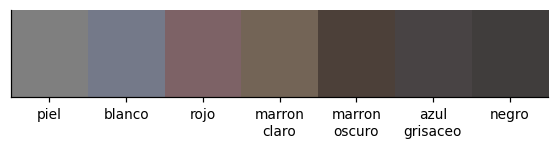

In [5]:
referencias = {c: (criterios_abc.referencia_de_color(p) if p else None) for c, p in pixeles_relativos.items()}
con_referencia = [c for c in COLORES if referencias[c] is not None]

fig, ax = plt.subplots(figsize=(16 / 2.54, 2.6 / 2.54))
muestras = [(0, 0, criterios_abc.ESCALA_RELATIVA)] + [referencias[c] for c in con_referencia]
ax.imshow(color.hsv2rgb(np.array(muestras)[None]), aspect="auto")
ax.set_xticks(range(len(muestras)), ["piel"] + [c.replace("_", "\n") for c in con_referencia])
ax.set_yticks([])
ax.grid(False)
graficos.guardar_figura(fig, "m4_referencias_color")

print("Para copiar en criterios_abc.py:\nREFERENCIAS_HSV =", referencias)
pd.DataFrame({c: referencias[c] for c in con_referencia}, index=["H", "S", "V"]).T

**Resultado:** con la piel llevada a gris medio, los marrones quedan anaranjados (H entre 0,06 y 0,08), con el claro más claro que el oscuro; el blanco queda gris celeste (H = 0,63) porque es más azulado que la piel; y el azul grisáceo y el negro quedan casi sin saturación (S ≈ 0,07), es decir, grises oscuros. Su H no importa, ya que con tan poca saturación, en el cono quedan pegados al eje. El rojo queda con H = 0,98, del otro lado del 0 que los marrones, tira a rosado mientras que los marrones tiran a naranja, y su brillo queda entre el del marrón claro y el del blanco.

## 3. Medidas en las imágenes de entrenamiento

Para cada imagen de entrenamiento corremos M1 y M3, y sobre nuestra máscara medimos todo lo que no depende de un umbral: las dos fracciones de asimetría, los 8 valores de borde con cada medida, la fracción de la lesión que ocupa cada color y la circularidad. Los umbrales se eligen después sobre la tabla, sin volver a procesar las imágenes.

La tabla se guarda en `resultados/m4_medidas_entrenamiento.csv` y se vuelve a calcular sola si cambian las referencias de color (por ejemplo, al marcar el rojo). Si se cambia otra cosa del `.py`, hay que borrar el archivo.

In [6]:
ARCHIVO_MEDIDAS = Path("../../resultados/m4_medidas_entrenamiento.csv")
huella = repr(referencias)
medidas = None
if ARCHIVO_MEDIDAS.exists():
    medidas = pd.read_csv(ARCHIVO_MEDIDAS, dtype={"nombre": str}).set_index("nombre")
    if medidas["referencias"].iloc[0] != huella:
        medidas = None

if medidas is None:
    filas = []
    inicio = time.time()
    for i, nombre in enumerate(entrenamiento, start=1):
        caso = carga_de_datos.cargar_caso(nombre, tabla)
        mejorada, valida, _ = mejoramiento.mejorar(caso.imagen)
        nuestra = segmentacion.segmentar(mejorada, valida)
        fila = {"nombre": nombre, "diagnostico": caso.diagnostico, "A_derm": caso.asimetria,
                "C_derm": caso.c_dermatologo, "colores_derm": " ".join(caso.colores)}
        for mascara, sufijo in ((nuestra, ""), (caso.mascara_ref, "_ph2")):
            f_mayor, f_menor, _ = criterios_abc.fracciones_asimetria(mascara)
            fila.update({f"f_mayor{sufijo}": f_mayor, f"f_menor{sufijo}": f_menor,
                         f"circularidad{sufijo}": criterios_abc.circularidad(mascara)})
            for medida in criterios_abc.MEDIDAS_BORDE:
                for k, valor in enumerate(criterios_abc.gradiente_por_sector(mejorada, mascara, medida)):
                    fila[f"{medida}{sufijo}_{k}"] = valor
            for nombre_color, fraccion in criterios_abc.fracciones_de_color(mejorada, mascara, referencias).items():
                fila[f"{nombre_color}{sufijo}"] = fraccion
        filas.append(fila)
        if i % 20 == 0:
            print(f"{i} imágenes ({(time.time() - inicio) / 60:.1f} min)")
    medidas = pd.DataFrame(filas).set_index("nombre").assign(referencias=huella)
    medidas.to_csv(ARCHIVO_MEDIDAS)

medidas["sospechosa"] = medidas["diagnostico"] > 0
medidas["diagnóstico"] = medidas["diagnostico"].map(carga_de_datos.DIAGNOSTICOS)
print(f"{len(medidas)} imágenes de entrenamiento: {medidas['sospechosa'].sum()} sospechosas y "
      f"{(~medidas['sospechosa']).sum()} nevos comunes")

140 imágenes de entrenamiento: 84 sospechosas y 56 nevos comunes


In [7]:
def sectores(medida, sufijo=""):
    """Los 8 valores de borde de cada imagen (una fila por imagen)."""
    return medidas[[f"{medida}{sufijo}_{k}" for k in range(criterios_abc.SECTORES)]].to_numpy()


def fracciones(sufijo=""):
    """Fracción de cada color en cada imagen, como lista de dicts."""
    return [{c: fila[f"{c}{sufijo}"] for c in COLORES} for _, fila in medidas.iterrows()]


def contar_colores(fracciones_por_imagen, umbral):
    return np.array([len(criterios_abc.colores_presentes(f, umbral)) for f in fracciones_por_imagen])


def cargar(nombre):
    """Caso, imagen mejorada, zona válida y nuestra máscara de una imagen (para las figuras)."""
    caso = carga_de_datos.cargar_caso(nombre, tabla)
    mejorada, valida, _ = mejoramiento.mejorar(caso.imagen)
    return caso, mejorada, valida, segmentacion.segmentar(mejorada, valida)

## 4. Asimetría (A)

Probamos umbrales de 0,01 a 0,30 y nos quedamos con el que da el κ más alto con el A del dermatólogo. A la izquierda, la fracción no superpuesta del eje más asimétrico de cada imagen, separada según el A que puso el dermatólogo; a la derecha, el κ con cada umbral.

Umbral elegido: 0.11 (κ = 0.44). Coincide con el dermatólogo en 68% de las imágenes.


A nuestro,0,1,2,total
A del dermatólogo,,,,
0,64,9,7,80
1,12,7,4,23
2,5,8,24,37
total,81,24,35,140


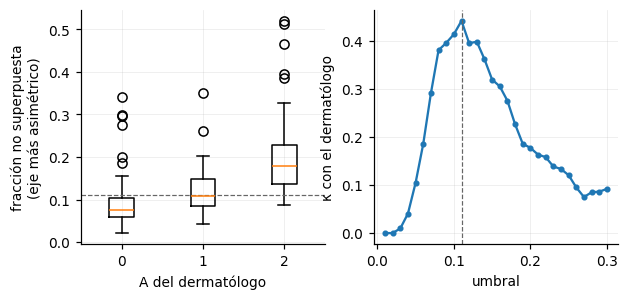

In [8]:
UMBRALES_A = np.round(np.arange(0.01, 0.301, 0.01), 2)
kappa_a = pd.Series({u: kappa_cohen(medidas["A_derm"],
                                    criterios_abc.contar_ejes_asimetricos(medidas["f_mayor"], medidas["f_menor"], u))
                     for u in UMBRALES_A})
umbral_a = float(kappa_a.idxmax())
medidas["A"] = criterios_abc.contar_ejes_asimetricos(medidas["f_mayor"], medidas["f_menor"], umbral_a)

fig, ax = plt.subplots(1, 2)
mas_asimetrico = medidas[["f_mayor", "f_menor"]].max(axis=1)
ax[0].boxplot([mas_asimetrico[medidas["A_derm"] == a] for a in (0, 1, 2)])
ax[0].set_xticks([1, 2, 3], ["0", "1", "2"])
ax[0].axhline(umbral_a, color="0.4", lw=0.8, ls="--")
ax[0].set_xlabel("A del dermatólogo")
ax[0].set_ylabel("fracción no superpuesta\n(eje más asimétrico)")
ax[1].plot(kappa_a.index, kappa_a.values, marker=".")
ax[1].axvline(umbral_a, color="0.4", lw=0.8, ls="--")
ax[1].set_xlabel("umbral")
ax[1].set_ylabel("κ con el dermatólogo")
graficos.guardar_figura(fig, "m4_asimetria_umbral")

print(f"Umbral elegido: {umbral_a:.2f} (κ = {kappa_a.max():.2f}). Coincide con el dermatólogo en "
      f"{np.mean(medidas['A'] == medidas['A_derm']):.0%} de las imágenes.")
pd.crosstab(medidas["A_derm"].rename("A del dermatólogo"), medidas["A"].rename("A nuestro"),
            margins=True, margins_name="total")

**Resultado:** el mejor umbral es 0,11, es decir que un eje es asimétrico si más del 11 % de la lesión queda sin pareja al doblarla por ese eje. Con él, κ = 0,44 (acuerdo moderado) y coincidimos exactamente con el dermatólogo en el 68 % de las imágenes. En el gráfico de la izquierda se ve que la fracción crece con el A del dermatólogo, aunque los grupos se superponen bastante.

En la tabla se ve que casi todo el acuerdo está en los extremos. De las 80 lesiones que el dermatólogo marcó como simétricas, nosotros decimos A = 0 en 64, y de las 37 con A = 2, decimos 2 en 24. El A = 1 es el más difícil (acertamos 7 de 23). Por último, los desacuerdos grandes (decir 0 cuando él dice 2, o al revés) son pocos: 12 de 140.

Tres ejemplos: una lesión donde los dos decimos A = 0, una donde los dos decimos A = 2 y una donde el dermatólogo dice 2 y nosotros 0. Cada una se eligió al azar (con semilla fija) dentro de su grupo.

WindowsPath('D:/Datos Facu No Borrar/Escritorio/TP final Imágense/informe/figuras/m4_asimetria_ejemplos.pdf')

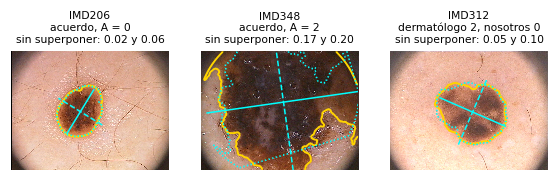

In [9]:
ejemplos = {
    "acuerdo, A = 0": medidas[(medidas["A_derm"] == 0) & (medidas["A"] == 0)],
    "acuerdo, A = 2": medidas[(medidas["A_derm"] == 2) & (medidas["A"] == 2)],
    "dermatólogo 2, nosotros 0": medidas[(medidas["A_derm"] == 2) & (medidas["A"] == 0)],
}
fig, ax = plt.subplots(1, 3, figsize=(16 / 2.54, 5 / 2.54))
for a, (titulo, grupo) in zip(ax, ejemplos.items()):
    if grupo.empty:
        a.set_axis_off()
        continue
    nombre = grupo.sample(1, random_state=0).index[0]
    caso, mejorada, _, mascara = cargar(nombre)
    dibujar_ejes(a, caso.imagen, mascara, f"{nombre}\n{titulo}")
graficos.guardar_figura(fig, "m4_asimetria_ejemplos")

**Resultado:** en IMD206 la lesión es casi un óvalo y su reflejo coincide casi entero (0,02 y 0,06). IMD348 es una lesión enorme que se sale de la foto. Como lo que se refleja afuera de la imagen cuenta como no superpuesto, en las lesiones cortadas por el borde A tiende a salir más alto; en este caso coincide con el dermatólogo.

En IMD312 la forma es bastante simétrica (0,05 y 0,10, apenas debajo del umbral), pero el dermatólogo puso A = 2. En la imagen se ve que el pigmento no está repartido parejo, hay una zona más oscura de un lado. Y acá está la clave, el dermatólogo evalúa también si los colores y las estructuras están repartidos de forma simétrica, y nosotros sólo miramos la forma del contorno. Es la principal limitación de este criterio.

## 5. Borde (B)

### 5.1 ¿Qué medida y qué umbral?

Como PH2 no anota B, el umbral se elige como el que hace que B mejor separe los nevos comunes de las lesiones sospechosas (el AUC más alto). Probamos, para cada medida, como cambia con el percentil (del 5 al 95) de todos los valores de sector de entrenamiento. Nuestra hipótesis era que la medida normalizada iba a separar mejor.

Elegida: medida crudo, umbral 0.0513 (percentil 80), AUC = 0.59


,percentil,umbral,B medio,AUC
medida,,,,
crudo,80,0.051,1.593,0.587
normalizado,85,1.050,1.200,0.381


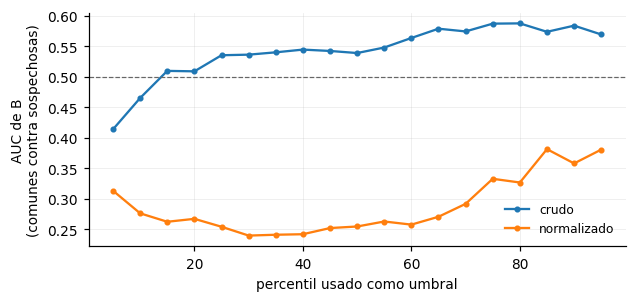

In [10]:
filas = []
for medida in criterios_abc.MEDIDAS_BORDE:
    valores = sectores(medida)
    for p in range(5, 100, 5):
        umbral = float(f"{np.nanpercentile(valores, p):.3g}")
        b = criterios_abc.contar_sectores_abruptos(valores, umbral)
        filas.append({"medida": medida, "percentil": p, "umbral": umbral, "B medio": b.mean(),
                      "AUC": auc(b, medidas["sospechosa"])})
grilla_b = pd.DataFrame(filas)

fig, ax = plt.subplots()
for medida, grupo in grilla_b.groupby("medida"):
    ax.plot(grupo["percentil"], grupo["AUC"], marker=".", label=medida)
ax.axhline(0.5, color="0.4", lw=0.8, ls="--")
ax.set_xlabel("percentil usado como umbral")
ax.set_ylabel("AUC de B\n(comunes contra sospechosas)")
ax.legend()
graficos.guardar_figura(fig, "m4_borde_medidas")

mejor_b = grilla_b.loc[grilla_b["AUC"].idxmax()]
medida_b, umbral_b = mejor_b["medida"], float(mejor_b["umbral"])
print(f"Elegida: medida {medida_b}, umbral {umbral_b} (percentil {mejor_b['percentil']}), AUC = {mejor_b['AUC']:.2f}")
grilla_b.loc[grilla_b.groupby("medida")["AUC"].idxmax()].set_index("medida").round(3)

**Resultado:** nuestra hipótesis no se cumplió. Si bien la medida cruda separa poco (con el umbral del percentil 80 llega a un AUC de 0,59), la normalizada da un AUC menor que 0,5 con cualquier umbral (entre 0,24 y 0,38), o sea que separa, pero **al revés**. Con ella, los nevos comunes tienen más sectores abruptos que las lesiones sospechosas, y eso no se condice con la teoría.

En PH2, el borde de los nevos comunes es más nítido que el de las lesiones sospechosas (en cuanto a contraste). Mirando las imágenes tiene sentido: los nevos comunes suelen ser manchas chicas y parejas con el borde bien marcado, mientras que los atípicos y los melanomas suelen tener bordes que se van desvaneciendo. La regla ABCD cuenta como sospechoso el pigmento que termina de golpe, pero en esta base eso no aparece en el gradiente.

Por lo tanto, **elegimos la medida cruda**, con el umbral 0,0513, porque es la única que suma en la dirección que espera el TDS (más B, más sospechosa). De todas formas, como en el TDS cada sector pesa sólo 0,1, B va a influir poco en la clasificación.

### 5.2 B con la medida y el umbral elegidos

In [12]:
medidas["B"] = criterios_abc.contar_sectores_abruptos(sectores(medida_b), umbral_b)
resumen_b = medidas.groupby("diagnóstico")["B"].agg(imágenes="size", **{"B medio": "mean", "mediana": "median"})
display(resumen_b.round(2))
pd.crosstab(medidas["diagnóstico"], medidas["B"].rename("B"))

,imágenes,B medio,mediana
diagnóstico,,,
melanoma,28,1.86,1.5
nevo atípico,56,1.77,0.5
nevo común,56,1.29,0.0


B,0,1,2,3,4,5,6,7,8
diagnóstico,,,,,,,,,
melanoma,6,8,6,3,3,1,1,0,0
nevo atípico,28,8,4,3,5,1,1,5,1
nevo común,33,7,4,3,2,4,1,2,0


WindowsPath('D:/Datos Facu No Borrar/Escritorio/TP final Imágense/informe/figuras/m4_borde_ejemplo.pdf')

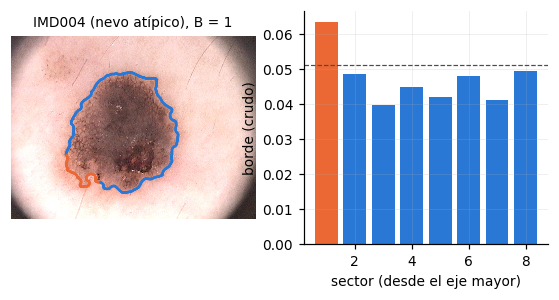

In [13]:
# Un ejemplo: la imagen de entrenamiento cuyo B está más cerca de la mediana
nombre = (medidas["B"] - medidas["B"].median()).abs().idxmin()
caso, mejorada, valida, mascara = cargar(nombre)
valores = criterios_abc.gradiente_por_sector(mejorada, mascara, medida_b)
filas_c, columnas_c, sector = criterios_abc.contorno_por_sector(mascara, valida)
abrupto = np.nan_to_num(valores, nan=-np.inf) > umbral_b

fig, ax = plt.subplots(1, 2)
graficos.mostrar(ax[0], caso.imagen, f"{nombre} ({carga_de_datos.DIAGNOSTICOS[caso.diagnostico]}), B = {abrupto.sum()}")
ax[0].scatter(columnas_c, filas_c, s=0.3,
              c=np.where(abrupto[sector], graficos.COLOR_GRUPO["sospechosa"], graficos.COLOR_GRUPO["comun"]))
ax[1].bar(np.arange(1, criterios_abc.SECTORES + 1), valores,
          color=np.where(abrupto, graficos.COLOR_GRUPO["sospechosa"], graficos.COLOR_GRUPO["comun"]))
ax[1].axhline(umbral_b, color="0.3", lw=0.8, ls="--")
ax[1].set_xlabel("sector (desde el eje mayor)")
ax[1].set_ylabel(f"borde ({medida_b})")
graficos.guardar_figura(fig, "m4_borde_ejemplo")

**Resultado:** con la medida y el umbral elegidos, B queda bajo en general (mediana 0 en los nevos comunes, 0,5 en los atípicos y 1,5 en los melanomas). El orden entre diagnósticos es el esperado, pero las distribuciones se superponen mucho: hay nevos comunes con 5 o más sectores abruptos y melanomas con ninguno. En el ejemplo (IMD004, un nevo atípico) sólo un sector supera el umbral (en naranja); los otros siete quedan cerca, pero por debajo.

## 6. Color (C)

### 6.1 La fracción mínima

Probamos fracciones mínimas entre 0,5 % y 20 % de la lesión y nos quedamos con la que da el κ más alto con el C del dermatólogo.

In [14]:
UMBRALES_C = [0.005, 0.01, 0.02, 0.03, 0.05, 0.075, 0.1, 0.15, 0.2]
fracciones_nuestras = fracciones()
kappa_c = pd.Series({u: kappa_cohen(medidas["C_derm"], contar_colores(fracciones_nuestras, u)) for u in UMBRALES_C})
umbral_c = float(kappa_c.idxmax())
medidas["C"] = contar_colores(fracciones_nuestras, umbral_c)
medidas["colores"] = [" ".join(criterios_abc.colores_presentes(f, umbral_c)) for f in fracciones_nuestras]

print(f"Fracción mínima elegida: {umbral_c:.1%} (κ = {kappa_c.max():.2f}). C coincide exacto en "
      f"{np.mean(medidas['C'] == medidas['C_derm']):.0%} de las imágenes y con diferencia de "
      f"a lo sumo 1 en {np.mean(abs(medidas['C'] - medidas['C_derm']) <= 1):.0%}.")
display(kappa_c.rename("κ de C").rename_axis("fracción mínima").to_frame().T.round(3))
pd.crosstab(medidas["C_derm"].rename("C del dermatólogo"), medidas["C"].rename("C nuestro"),
            margins=True, margins_name="total")

Fracción mínima elegida: 5.0% (κ = 0.17). C coincide exacto en 39% de las imágenes y con diferencia de a lo sumo 1 en 81%.


fracción mínima,0.005,0.010,0.020,0.030,0.050,0.075,0.100,0.150,0.200
κ de C,0.012,0.053,0.125,0.133,0.17,0.165,0.117,0.086,0.062


C nuestro,1,2,3,4,5,total
C del dermatólogo,,,,,,
1,15,12,5,8,1,41
2,15,29,17,8,1,70
3,2,4,4,7,0,17
4,0,0,2,7,1,10
5,0,0,1,1,0,2
total,32,45,29,31,3,140


**Resultado:** el acuerdo en C es bajo: con la mejor fracción mínima (5 %), κ = 0,17. Coincidimos exactamente en el 39 % de las imágenes, aunque en el 81 % la diferencia es de un color como mucho. En la tabla se ve que en las lesiones de un solo color solemos encontrar más (en 26 de 41), mientras que las de cuatro colores las reconocemos bastante bien (7 de 10).

### 6.2 Color por color

El κ de C sólo mira cuántos colores hay, no cuáles. Para ver cuáles encontramos bien, comparamos color por color: en cuántas imágenes lo anotó el dermatólogo, en cuántas de esas lo encontramos y en cuántas lo encontramos sin que él lo anotara.

In [15]:
def acuerdo_por_color(colores_derm, colores_nuestros):
    filas = []
    for c in COLORES:
        derm = colores_derm.str.split().apply(lambda lista: c in lista)
        nuestro = colores_nuestros.str.split().apply(lambda lista: c in lista)
        filas.append({"color": c, "lo anotó el dermatólogo": derm.sum(), "de esas, lo encontramos": (derm & nuestro).sum(),
                      "lo encontramos sin que lo anote": (~derm & nuestro).sum(), "κ": kappa_cohen(derm, nuestro)})
    return pd.DataFrame(filas).set_index("color")


display(acuerdo_por_color(medidas["colores_derm"], medidas["colores"]).round(2))
medidas.groupby("diagnóstico")[list(COLORES) + ["piel"]].mean().mul(100).round(1).rename_axis("% de la lesión")

,lo anotó el dermatólogo,"de esas, lo encontramos",lo encontramos sin que lo anote,κ
color,,,,
blanco,16,1,2,0.07
rojo,7,1,10,0.05
marron_claro,96,96,42,0.06
marron_oscuro,108,88,14,0.35
azul_grisaceo,25,21,26,0.46
negro,30,24,23,0.49


,blanco,rojo,marron_claro,marron_oscuro,azul_grisaceo,negro,piel
% de la lesión,,,,,,,
melanoma,2.3,1.2,30.0,23.0,18.1,15.1,10.3
nevo atípico,0.4,2.6,52.0,21.8,4.8,14.1,4.4
nevo común,0.1,2.1,76.3,16.1,1.2,2.5,1.7


**Resultado** color por color:
- **Marrón claro:** lo encontramos en todas las lesiones donde el dermatólogo lo anotó, pero también en 42 de las 44 donde no lo anotó. Esto probablemente ocurra porque es el color de casi todo el borde de la lesión, donde el pigmento se va aclarando hacia la piel, y con un 5 % alcanza para contarlo.
- **Blanco:** casi nunca lo encontramos (1 de 16). Puede estar pasando que las zonas blancas son tan claras como la piel blanca y seguramente el programa las manda a "parecido a la piel".
- **Rojo:** lo encontramos en 1 de las 7 imágenes donde el dermatólogo lo anotó, que es justo IMD035, de donde sacamos la referencia, y en 10 donde no lo anotó (κ = 0,05). Con una sola zona para armar la referencia, sabíamos de antemano que este criterio no iba a ser el mejor.
- **Marrón oscuro, azul grisáceo y negro:** andan mejor (κ entre 0,35 y 0,49), aunque el azul grisáceo y el negro también aparecen en lesiones donde el dermatólogo no los anotó (26 y 23 veces), en parte porque se confunden entre ellos.

### 6.3 Hacerlo adaptativo al color (un mínimo por color)

Viendo la tabla anterior, probamos hacerlo al revés, y darle a cada color su propia fracción mínima, que sea aquella que da el κ más alto de ese color con el dermatólogo.

In [16]:
propios = {}
for c in COLORES:
    derm = medidas["colores_derm"].str.split().apply(lambda lista: c in lista)
    kappas = {u: kappa_cohen(derm, medidas[c] >= u) for u in UMBRALES_C + [0.3, 0.4, 0.5]}
    propios[c] = max(kappas, key=kappas.get)
presentes = np.column_stack([medidas[c] >= propios[c] for c in COLORES])
c_propio = np.maximum(presentes.sum(axis=1), 1)
colores_propio = pd.Series([" ".join(c for c, p in zip(COLORES, fila) if p) for fila in presentes], index=medidas.index)

print("Fracción mínima de cada color:", {c: f"{u:.1%}" for c, u in propios.items()})
print(f"κ de C con un mínimo por color: {kappa_cohen(medidas['C_derm'], c_propio):.2f} "
      f"(con un único mínimo: {kappa_c.max():.2f})")
acuerdo_por_color(medidas["colores_derm"], colores_propio).round(2)

Fracción mínima de cada color: {'blanco': '0.5%', 'rojo': '30.0%', 'marron_claro': '50.0%', 'marron_oscuro': '15.0%', 'azul_grisaceo': '10.0%', 'negro': '20.0%'}
κ de C con un mínimo por color: 0.15 (con un único mínimo: 0.17)


,lo anotó el dermatólogo,"de esas, lo encontramos",lo encontramos sin que lo anote,κ
color,,,,
blanco,16,9,18,0.32
rojo,7,1,2,0.18
marron_claro,96,76,6,0.60
marron_oscuro,108,72,6,0.36
azul_grisaceo,25,16,13,0.50
negro,30,18,9,0.54


**Resultado:** con un mínimo propio, cada color por separado coincide mucho mejor con el dermatólogo. El marrón claro pasa de κ 0,06 a 0,60 (ahora tiene que ocupar la mitad de la lesión para contar), el blanco de 0,07 a 0,32, y el azul grisáceo y el negro llegan a 0,50 y 0,54. Pero el κ de C, que es lo que entra en el TDS, no mejora (0,15 contra 0,17). Como además serían seis umbrales elegidos con las mismas 140 imágenes, con más riesgo de que anden bien sólo en ellas (sería una especie de underfitting), nos quedamos con **un único mínimo de 5 %**.

### 6.4 Mapas de color

A continuación mostramos una lesión de cada diagnóstico, la que tiene más colores según el dermatólogo (si hay empate, la primera). Fuera de la lesión el fondo es gris claro, y los píxeles que se parecen más a la piel quedan en gris medio.

WindowsPath('D:/Datos Facu No Borrar/Escritorio/TP final Imágense/informe/figuras/m4_mapa_colores.pdf')

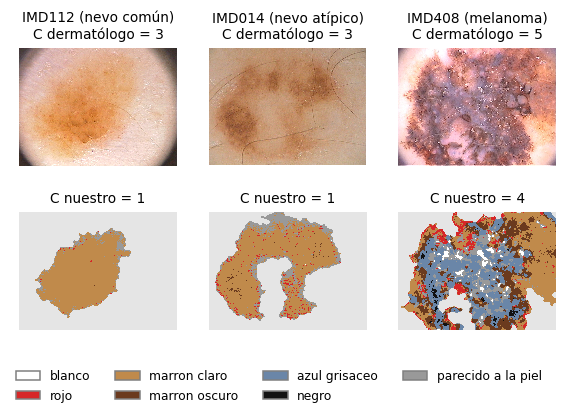

In [17]:
PINTURA = {"blanco": "#ffffff", "rojo": "#d62728", "marron_claro": "#c08a4b", "marron_oscuro": "#6b3a1e",
           "azul_grisaceo": "#6a86a8", "negro": "#111111"}
fig, ax = plt.subplots(2, 3, figsize=(16 / 2.54, 9 / 2.54))
for j, (diagnostico, grupo) in enumerate(medidas.groupby("diagnostico")):
    nombre = grupo["C_derm"].idxmax()
    caso, mejorada, _, mascara = cargar(nombre)
    mapa = criterios_abc.mapa_de_colores(mejorada, mascara, referencias)
    pintado = np.full((*mapa.shape, 3), 0.9)
    pintado[mapa == criterios_abc.PARECIDO_A_PIEL] = 0.6
    for k, c in enumerate(COLORES):
        pintado[mapa == k] = to_rgb(PINTURA[c])
    graficos.mostrar(ax[0, j], caso.imagen, f"{nombre} ({carga_de_datos.DIAGNOSTICOS[diagnostico]})\n"
                                           f"C dermatólogo = {caso.c_dermatologo}")
    graficos.mostrar(ax[1, j], pintado, f"C nuestro = {medidas.loc[nombre, 'C']}")
fig.legend(handles=[Patch(facecolor=PINTURA[c], edgecolor="0.5", label=c.replace("_", " ")) for c in COLORES]
           + [Patch(facecolor="0.6", edgecolor="0.5", label="parecido a la piel")], loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.08))
graficos.guardar_figura(fig, "m4_mapa_colores")

**Resultado:** en los dos nevos casi toda la lesión queda como marrón claro, así que nuestro C es 1, mientras que el dermatólogo vio 3 colores. En IMD112 anotó además rojo y marrón oscuro, pero nosotros encontramos apenas un 0,6 % de rojo y nada de marrón oscuro, y en IMD014 anotó blanco, que nosotros mandamos a "parecido a la piel". En el melanoma IMD408 aparecen marrón claro, marrón oscuro y azul grisáceo, que también anotó el dermatólogo, y un 6 % de rojo que él no anotó, pero se nos escapan el blanco y el negro, que no llegan al 5 % de la lesión (2,6 % y 1,4 %).

## 7. Circularidad

,imágenes,media,mediana
diagnóstico,,,
melanoma,28,0.356,0.340
nevo atípico,56,0.597,0.616
nevo común,56,0.683,0.710


AUC (menos circular = más sospechosa): 0.75


WindowsPath('D:/Datos Facu No Borrar/Escritorio/TP final Imágense/informe/figuras/m4_circularidad.pdf')

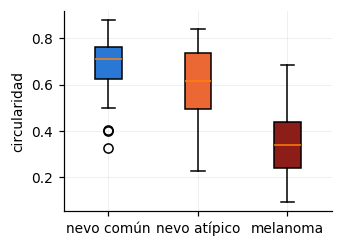

In [18]:
display(medidas.groupby("diagnóstico")["circularidad"].agg(imágenes="size", media="mean", mediana="median").round(3))
print(f"AUC (menos circular = más sospechosa): {auc(-medidas['circularidad'], medidas['sospechosa']):.2f}")

fig, ax = plt.subplots(figsize=(8 / 2.54, 6 / 2.54))
orden = [carga_de_datos.DIAGNOSTICOS[d] for d in (0, 1, 2)]
partes = ax.boxplot([medidas.loc[medidas["diagnóstico"] == d, "circularidad"] for d in orden], patch_artist=True)
for caja, d in zip(partes["boxes"], (0, 1, 2)):
    caja.set_facecolor(graficos.COLOR_DIAGNOSTICO[d])
ax.set_xticks([1, 2, 3], orden)
ax.set_ylabel("circularidad")
graficos.guardar_figura(fig, "m4_circularidad")

**Resultado:** la circularidad separa bien: los melanomas son bastante menos circulares (mediana 0,34) que los nevos atípicos (0,62) y los comunes (0,71), y el AUC es 0,75, el mejor de los criterios hasta ahora.

## 8. ¿El error viene de la segmentación o del criterio?

Repetimos todo con la máscara de PH2 en vez de la nuestra. Para que la comparación sea justa, a cada máscara le buscamos su propio mejor umbral, con las mismas listas de valores que antes (si no, la nuestra saldría favorecida, porque los umbrales se eligieron con ella). Si con la máscara de PH2 el acuerdo es mucho mejor, el problema está en M3; si es parecido, está en cómo medimos el criterio.

In [19]:
sos = medidas["sospechosa"]
comparacion = {}
for mascara, sufijo in (("nuestra máscara", ""), ("máscara de PH2", "_ph2")):
    kappas_a = pd.Series({u: kappa_cohen(medidas["A_derm"], criterios_abc.contar_ejes_asimetricos(
        medidas[f"f_mayor{sufijo}"], medidas[f"f_menor{sufijo}"], u)) for u in UMBRALES_A})
    kappas_c = pd.Series({u: kappa_cohen(medidas["C_derm"], contar_colores(fracciones(sufijo), u)) for u in UMBRALES_C})
    valores_b = sectores(medida_b, sufijo)
    aucs_b = pd.Series({p: auc(criterios_abc.contar_sectores_abruptos(valores_b, np.nanpercentile(valores_b, p)), sos)
                        for p in range(5, 100, 5)})
    comparacion[mascara] = {"κ de A": kappas_a.max(), "  con el umbral": kappas_a.idxmax(),
                            "κ de C": kappas_c.max(), "  con la fracción mínima": kappas_c.idxmax(),
                            "AUC de B": aucs_b.max(), "AUC de la circularidad": auc(-medidas[f"circularidad{sufijo}"], sos),
                            "circularidad media": medidas[f"circularidad{sufijo}"].mean()}
pd.DataFrame(comparacion).round(3)

,nuestra máscara,máscara de PH2
κ de A,0.441,0.294
con el umbral,0.110,0.090
κ de C,0.170,0.165
con la fracción mínima,0.050,0.075
AUC de B,0.589,0.550
AUC de la circularidad,0.754,0.574
circularidad media,0.583,0.682


**Resultado:** sorprendentemente, con la máscara de PH2 no anda mejor, sino peor: aun con su propio mejor umbral, el κ de A baja de 0,44 a 0,29 y el AUC de la circularidad de 0,75 a 0,57. En C y en B da más o menos lo mismo. Entonces, los desacuerdos con el dermatólogo no vienen de M3 sino de los criterios en sí.

¿Por qué nuestra máscara anda mejor? En M3 vimos que se queda corta sobre todo en los melanomas, porque deja afuera las partes claras o azuladas y sigue la zona de pigmento más oscuro. Entonces su morfología, de cierta forma, TAMBIÉN refleja cómo está repartido el pigmento adentro de la lesión, que es algo que el dermatólogo mira para A y que el contorno completo de la lesión pensabamos que no mostraba. Con la circularidad pasa algo parecido: nuestra máscara es en promedio menos circular (0,58 contra 0,68), y en los melanomas, donde se queda más corta, queda más irregular.

## 9. Valores elegidos

Los valores elegidos en las secciones anteriores se copian a mano en `criterios_abc.py`, que es lo que usan el resto del programa y la interfaz. Esta celda comprueba que coincidan.

In [20]:
elegidos = {"UMBRAL_ASIMETRIA": umbral_a, "MEDIDA_BORDE": medida_b, "UMBRAL_BORDE": umbral_b,
            "FRACCION_MIN_COLOR": umbral_c, "REFERENCIAS_HSV": referencias}
for nombre, valor in elegidos.items():
    en_el_py = getattr(criterios_abc, nombre)
    estado = "ok" if en_el_py == valor else "DISTINTO: actualizar criterios_abc.py"
    print(f"{nombre}: {estado}" + ("" if en_el_py == valor else f"\n   cuaderno: {valor}\n   .py:      {en_el_py}"))

UMBRAL_ASIMETRIA: ok
MEDIDA_BORDE: ok
UMBRAL_BORDE: ok
FRACCION_MIN_COLOR: ok
REFERENCIAS_HSV: ok


## 10. Resultados en prueba

Con los valores ya fijados en `criterios_abc.py`, corremos todo el programa hasta M4 sobre las 60 imágenes de prueba, que no se usaron para elegir nada.

In [21]:
CORRER_PRUEBA = True
if CORRER_PRUEBA:
    filas = []
    for nombre in carga_de_datos.nombres("prueba"):
        caso = carga_de_datos.cargar_caso(nombre, tabla)
        criterios = procesar(caso, hasta="criterios_abc").criterios
        filas.append({"nombre": nombre, "diagnostico": caso.diagnostico, "A_derm": caso.asimetria,
                      "C_derm": caso.c_dermatologo, "colores_derm": " ".join(caso.colores),
                      **{k: criterios[k] for k in ("A", "B", "C", "circularidad")},
                      "colores": " ".join(criterios["colores"])})
    prueba = pd.DataFrame(filas).set_index("nombre")

    def resumir(t):
        sospechosa = t["diagnostico"] > 0
        return {"κ de A": kappa_cohen(t["A_derm"], t["A"]),
                "A coincide exacto": np.mean(t["A"] == t["A_derm"]),
                "κ de C": kappa_cohen(t["C_derm"], t["C"]),
                "C coincide exacto": np.mean(t["C"] == t["C_derm"]),
                "C con diferencia de a lo sumo 1": np.mean(abs(t["C"] - t["C_derm"]) <= 1),
                "AUC de B": auc(t["B"], sospechosa),
                "AUC de la circularidad": auc(-t["circularidad"], sospechosa)}

    resumen = pd.DataFrame({"entrenamiento": resumir(medidas), "prueba": resumir(prueba)})
    graficos.guardar_tabla(resumen.reset_index(names="medida"), "m4_resumen", decimales=2)
    display(resumen.round(2))
    display(pd.crosstab(prueba["A_derm"].rename("A del dermatólogo"), prueba["A"].rename("A nuestro")))
    display(acuerdo_por_color(prueba["colores_derm"], prueba["colores"]).round(2))

,entrenamiento,prueba
κ de A,0.44,0.38
A coincide exacto,0.68,0.67
κ de C,0.17,0.24
C coincide exacto,0.39,0.45
C con diferencia de a lo sumo 1,0.81,0.80
AUC de B,0.59,0.60
AUC de la circularidad,0.75,0.72


A nuestro,0,1,2
A del dermatólogo,,,
0,30,5,2
1,4,1,3
2,3,3,9


,lo anotó el dermatólogo,"de esas, lo encontramos",lo encontramos sin que lo anote,κ
color,,,,
blanco,3,0,3,-0.05
rojo,3,1,4,0.20
marron_claro,43,43,15,0.16
marron_oscuro,48,45,5,0.56
azul_grisaceo,13,12,10,0.57
negro,12,12,14,0.49


**Resultado:** en prueba los números son parecidos a los de entrenamiento, así que los umbrales no quedaron ajustados sólo a esas 140 imágenes: κ de A 0,38 (contra 0,44), AUC de B 0,60 (contra 0,59) y AUC de la circularidad 0,72 (contra 0,75). El κ de C sube a 0,24 (contra 0,17), y la otra medida de C (diferencia de un color como mucho) da casi igual: 80 % contra 81 %. Color por color se repite lo de entrenamiento: el marrón claro aparece de más, el blanco no lo encontramos y el rojo casi nunca (1 de 3), y el marrón oscuro, el azul grisáceo y el negro andan razonablemente (κ entre 0,49 y 0,57).